# DSSAT CROPGRO-Soybean emulator: what it does and how to use it

`cropemu` ships an emulator of **DSSAT 4.8 CROPGRO-Soybean**: a neural network trained on ~118,000 simulated
seasons at ~2,000 points of the world soybean area (NASA POWER weather, SoilGrids soil, GGCMI
calendar). It predicts the phenology, yield, biomass and water balance of a season from the
weather, the soil, the sowing date and the cultivar, in microseconds instead of the
0.1-1 s of the crop model, and without installing it.

This notebook is a tour of the library with one site (Londrina, Brazil) and one region:

1. the emulator: outputs, units, validation error, training domain;
2. weather and soil of a site;
3. one season, and how to read a prediction;
4. 35 years at a fixed sowing date;
5. the sowing window (year × sowing date);
6. cultivars and parameter sensitivity;
7. water: rainfed vs. irrigated;
8. climate scenarios (warming, CO₂, rain);
9. a regional map;
10. speed;
11. your own data: station weather, measured soil, the cultivar of a trial, comparison with field
    observations and calibration, illustrated with published field trials.

Everything here runs with `pip install "cropemu[soil]"`; weather and soil are downloaded once and
cached (`CROPEMU_CACHE`, default `~/.cache/cropemu`).

In [1]:
try:
    import cropemu
    assert tuple(int(v) for v in cropemu.__version__.split(".")[:2]) >= (0, 2)
except (ImportError, AssertionError):     # install from PyPI (Intel Macs need --prefer-binary for rasterio)
    %pip install --quiet --prefer-binary "cropemu[soil]>=0.2"
    import cropemu

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cropemu.weather import fetch, fill_gaps
from cropemu.soil import soilgrids, hydraulics

print("cropemu", cropemu.__version__, "| emulators:", cropemu.available())

cropemu 0.3.1 | emulators: ['aquacrop-soybean-v1', 'dssat-soybean-v1']


In [2]:
# figure style: recessive axes, fixed colour order
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
LEVEL_COLOR = {"recommended": "#0ca30c", "caution": "#fab219", "not recommended": "#d03b3b"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "0.9", "grid.linewidth": 0.6, "axes.edgecolor": "0.6",
                     "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "legend.frameon": False, "figure.dpi": 110,
                     "axes.prop_cycle": plt.cycler(color=SERIES)})

YLD, MAT, FLO, ET, RAIN, BIO = 'HWAM', 'MDAT_dap', 'ADAT_dap', 'ETCM', 'PRCM', 'CWAM'
TO_T = 1e-3            # yield to t/ha
BIO_T = 1e-3           # biomass to t/ha

## 1. The emulator

In [3]:
emu = cropemu.load('dssat-soybean-v1')
print(emu)
print("trained on:", emu.card["training"]["seasons"], "seasons at", emu.card["training"]["points"], "points")
print("validation:", emu.card["validation"])
print("soil water retention:", emu.card["hydraulics"], "| cultivar parameters:", emu.cultivar_)
desc = emu.describe()
desc.round(3)

Emulator('dssat-soybean-v1': DSSAT 4.8 CROPGRO-Soybean (official executable), soybean; 79 inputs, 39 outputs)
trained on: 117720 seasons at 1962 points
validation: 5-fold cross-validation by 5-degree spatial blocks (out-of-fold metrics)
soil water retention: hybrid | cultivar parameters: ['mg', 'CSDL', 'PPSEN', 'EM-FL', 'FL-SH', 'FL-SD', 'SD-PM', 'FL-LF', 'LFMAX', 'SLAVR', 'SIZLF', 'WTPSD', 'SFDUR', 'SDPDV']


,description,unit,level,rmse,r2
output,,,,,
EDAT_dap,emergence date,days after sowing,recommended,3.553,0.878
ADAT_dap,anthesis (flowering) date,days after sowing,recommended,3.199,0.972
MDAT_dap,physiological maturity date,days after sowing,recommended,3.287,0.982
HDAT_dap,harvest date,days after sowing,caution,7.654,0.909
DWAP,planting material weight,kg/ha,recommended,0.453,0.989
CWAM,tops (above-ground) dry weight at maturity,kg/ha,caution,715.241,0.959
HWAM,grain yield at maturity (dry),kg/ha,caution,453.751,0.944
HWAH,harvested grain yield (dry),kg/ha,caution,452.705,0.944
PWAM,pod weight at maturity,kg/ha,caution,576.070,0.945


In [4]:
EMU_FAMILY = 'dssat'

Every output has an **acceptance level** from the spatial block validation (the network was tested
on 5° blocks it never saw):

- *recommended*: dates with RMSE ≤ 5 days, other outputs with RMSE < 0.25 of their within-site
  standard deviation;
- *caution*: relative error < 0.5;
- *not recommended*: use only as a rough indication.

The figure shows the validation R² of every output.

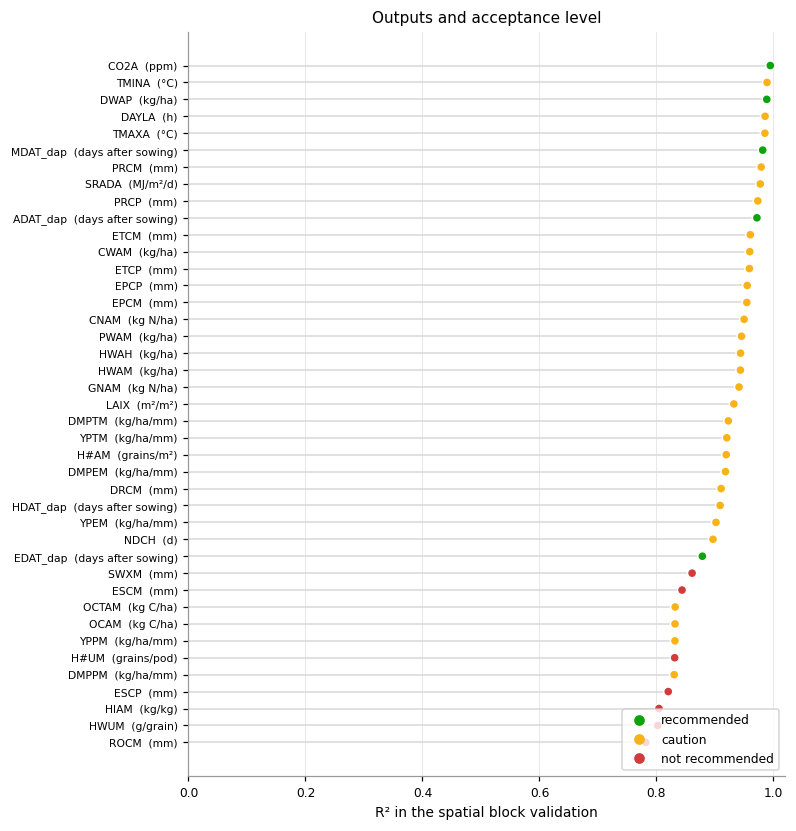

level
caution            29
not recommended     7
recommended         5


In [5]:
d = desc.dropna(subset=["r2"]).sort_values("r2")
fig, ax = plt.subplots(figsize=(7, 0.19 * len(d) + 1))
y = np.arange(len(d))
ax.hlines(y, 0, d["r2"].clip(lower=0), color="0.85", lw=1)
ax.scatter(d["r2"].clip(lower=0), y, s=36, color=[LEVEL_COLOR.get(l, "0.6") for l in d["level"]],
           edgecolor="white", linewidth=1, zorder=3)
ax.set_yticks(y, [f"{i}  ({u})" if u else i for i, u in zip(d.index, d["unit"])], fontsize=7)
ax.set(xlim=(0, 1.02), xlabel="R² in the spatial block validation", title="Outputs and acceptance level")
ax.grid(axis="y", visible=False)
ax.legend([plt.Line2D([], [], ls="", marker="o", color=v) for v in LEVEL_COLOR.values()], list(LEVEL_COLOR),
          loc="lower right", frameon=True)
plt.show()
print(d["level"].value_counts().to_string())

**Training domain.** The card stores the range of every input (min-max and 0.5-99.5 %).
Predictions report inputs outside it. The bars show the ranges of a few inputs.

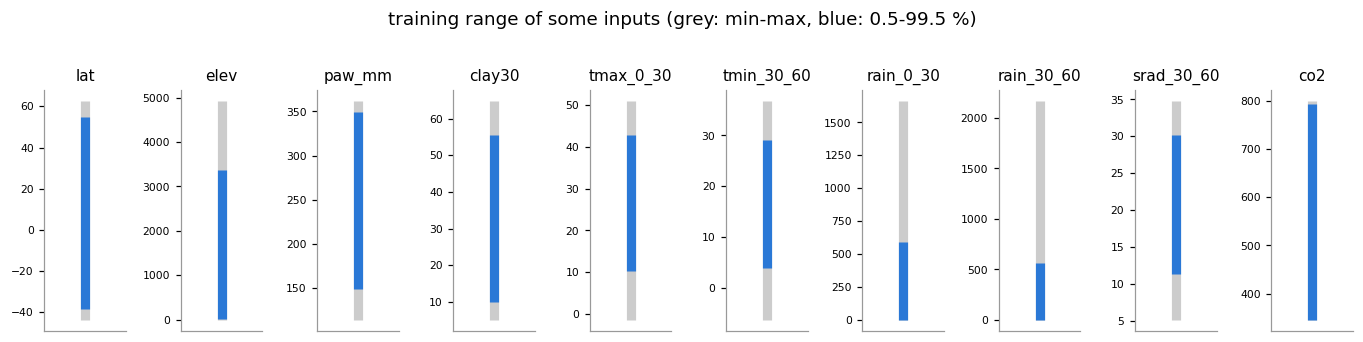

In [6]:
dom = pd.DataFrame(emu.card["domain"]).T
show = ["lat", "elev", "paw_mm", "clay30", "tmax_0_30", "tmin_30_60", "rain_0_30", "rain_30_60", "srad_30_60", "co2"]
fig, axes = plt.subplots(1, len(show), figsize=(1.25 * len(show), 3))
for ax, k in zip(axes, show):
    r = dom.loc[k]
    ax.vlines(0, r["min"], r["max"], color="0.8", lw=6)
    ax.vlines(0, r["q005"], r["q995"], color="#2a78d6", lw=6)
    ax.set(title=k, xticks=[]); ax.tick_params(labelsize=7); ax.grid(False)
fig.suptitle("training range of some inputs (grey: min-max, blue: 0.5-99.5 %)", y=1.02)
fig.tight_layout(); plt.show()

## 2. Weather and soil of a site

In [7]:
SITE, LAT, LON = "Londrina, Brazil", -23.19, -51.18
REF_SOWING = "2020-10-20"
weather = fill_gaps(fetch(LAT, LON, "1984-01-01", "2025-12-31"))        # NASA POWER, daily
ELEV = weather.attrs.get("elev", 600)
soil = soilgrids.fetch(LAT, LON)                                        # SoilGrids 2.0, 6 layers to 2 m
hyd = hydraulics(soil, method=emu.card["hydraulics"])                   # water retention used in training
print(f"{SITE}: elevation {ELEV:.0f} m, {len(weather)} days of weather")
hyd[["top", "bottom", "clay", "sand", "soc", "bdod", "ll", "dul", "sat"]].round(3)

Londrina, Brazil: elevation 455 m, 15341 days of weather


,top,bottom,clay,sand,soc,bdod,ll,dul,sat
0,0,5,42.4,23.7,3.93,1.20,0.295,0.453,0.547
1,5,15,41.9,24.3,2.48,1.23,0.274,0.431,0.536
2,15,30,46.4,22.1,1.77,1.22,0.270,0.426,0.540
3,30,60,53.3,18.6,1.04,1.22,0.277,0.428,0.540
4,60,100,54.2,18.4,0.67,1.22,0.272,0.423,0.540
5,100,200,51.9,19.4,0.70,1.22,0.266,0.418,0.540


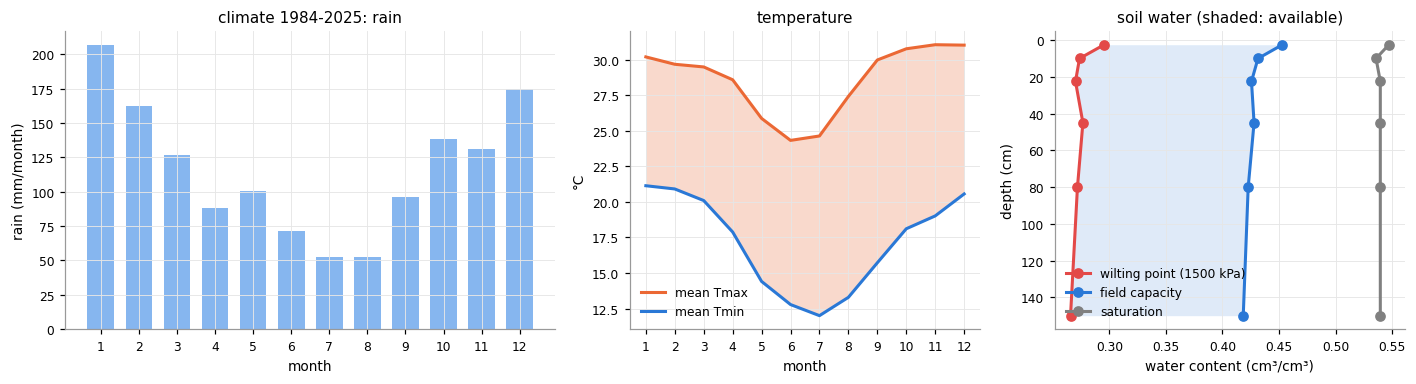

available water in 2 m: 306 mm


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.4, 1, 1]})
m = weather.groupby(weather.index.month).agg({"tmax": "mean", "tmin": "mean"})
rain = weather["rain"].groupby([weather.index.year, weather.index.month]).sum().groupby(level=1).mean()
ax = axes[0]
ax.bar(rain.index, rain, color="#86b6ef", width=0.7)
ax.set(xlabel="month", ylabel="rain (mm/month)", title="climate 1984-2025: rain")
ax.set_xticks(range(1, 13))
ax = axes[1]
ax.fill_between(m.index, m["tmin"], m["tmax"], color="#eb6834", alpha=0.25, lw=0)
ax.plot(m.index, m["tmax"], color="#eb6834", lw=2, label="mean Tmax")
ax.plot(m.index, m["tmin"], color="#2a78d6", lw=2, label="mean Tmin")
ax.set(xlabel="month", ylabel="°C", title="temperature"); ax.legend(); ax.set_xticks(range(1, 13))
ax = axes[2]
mid = (hyd["top"] + hyd["bottom"]) / 2
for col, lab, colr in (("ll", "wilting point (1500 kPa)", "#e34948"), ("dul", "field capacity", "#2a78d6"),
                       ("sat", "saturation", "0.5")):
    ax.plot(hyd[col], mid, marker="o", color=colr, lw=2, label=lab)
ax.fill_betweenx(mid, hyd["ll"], hyd["dul"], color="#2a78d6", alpha=0.15, lw=0)
ax.invert_yaxis(); ax.set(xlabel="water content (cm³/cm³)", ylabel="depth (cm)", title="soil water (shaded: available)")
ax.legend(loc="lower left")
fig.tight_layout(); plt.show()
paw = ((hyd["dul"] - hyd["ll"]) * (hyd["bottom"] - hyd["top"]) * 10).sum()
print(f"available water in 2 m: {paw:.0f} mm")

## 3. One season

### The cultivar

In DSSAT the cultivar is a set of 14 coefficients. `emu.cultivar(mg=...)` returns the
default coefficients of a maturity group (MG) from the CROPGRO-Soybean cultivar file;
`emu.cultivar(lat=...)` uses the typical MG of the latitude. Any coefficient can be overridden.

In [9]:
cult = emu.cultivar(lat=LAT)
cultivar_for = lambda mg: emu.cultivar(mg=mg)
pd.Series(cult).round(3).to_frame("value")

,value
mg,6.473
CSDL,12.462
PPSEN,0.315
EM-FL,20.484
FL-SH,9.473
FL-SD,16.000
SD-PM,35.978
FL-LF,18.000
LFMAX,1.030
SLAVR,375.000


In [10]:
res = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=REF_SOWING, cultivar=cult)
out = res.outputs.T.rename(columns=lambda d: f"sown {d:%Y-%m-%d}")
out = out.join(desc[["unit", "level"]]).round(3)
out

,sown 2020-10-20,unit,level
EDAT_dap,4.683,days after sowing,recommended
ADAT_dap,37.840,days after sowing,recommended
MDAT_dap,129.762,days after sowing,recommended
HDAT_dap,142.300,days after sowing,caution
DWAP,67.871,kg/ha,recommended
CWAM,4440.245,kg/ha,caution
HWAM,2653.344,kg/ha,caution
HWAH,2652.355,kg/ha,caution
PWAM,3531.516,kg/ha,caution
HWUM,0.192,g/grain,not recommended


A prediction carries, besides the outputs:

- `res.inputs`: the 80-odd inputs computed from weather, soil, sowing and cultivar (the same code as in training);
- `res.out_of_domain`: inputs outside the training range (do not trust the season);
- `res.rare_inputs`: inputs outside the 0.5-99.5 % range (less trust);
- `res.recommended("caution")`: only the outputs that passed the validation.

In [11]:
print("out of domain:", res.out_of_domain.iloc[0], "| rare:", res.rare_inputs.iloc[0])
res.recommended("recommended").round(2)

out of domain: [] | rare: []


,EDAT_dap,ADAT_dap,MDAT_dap,DWAP,CO2A
sowing,,,,,
2020-10-20,4.68,37.84,129.76,67.87,412.01


## 4. Thirty-five years at a fixed sowing date

In [12]:
YEARS = list(range(1990, 2025))
dates = [pd.Timestamp(y, 10, 20) for y in YEARS]
ts = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cult)
o = ts.outputs.assign(year=YEARS).set_index("year")
irr = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cult, irrigated=True).outputs
o["yield_t"] = o[YLD] * TO_T
o["yield_irrigated_t"] = irr[YLD].to_numpy() * TO_T
o[["yield_t", "yield_irrigated_t", MAT, ET, RAIN]].describe().round(2)

,yield_t,yield_irrigated_t,MDAT_dap,ETCM,PRCM
count,35.00,35.00,35.00,35.00,35.00
mean,4.85,5.77,126.07,672.85,891.97
std,1.22,0.33,3.63,42.86,226.10
min,1.56,5.07,114.53,556.02,532.43
25%,4.07,5.49,124.72,660.33,757.32
50%,5.39,5.88,126.67,675.21,872.19
75%,5.74,6.01,128.55,701.49,966.29
max,6.33,6.27,130.99,736.25,1561.30


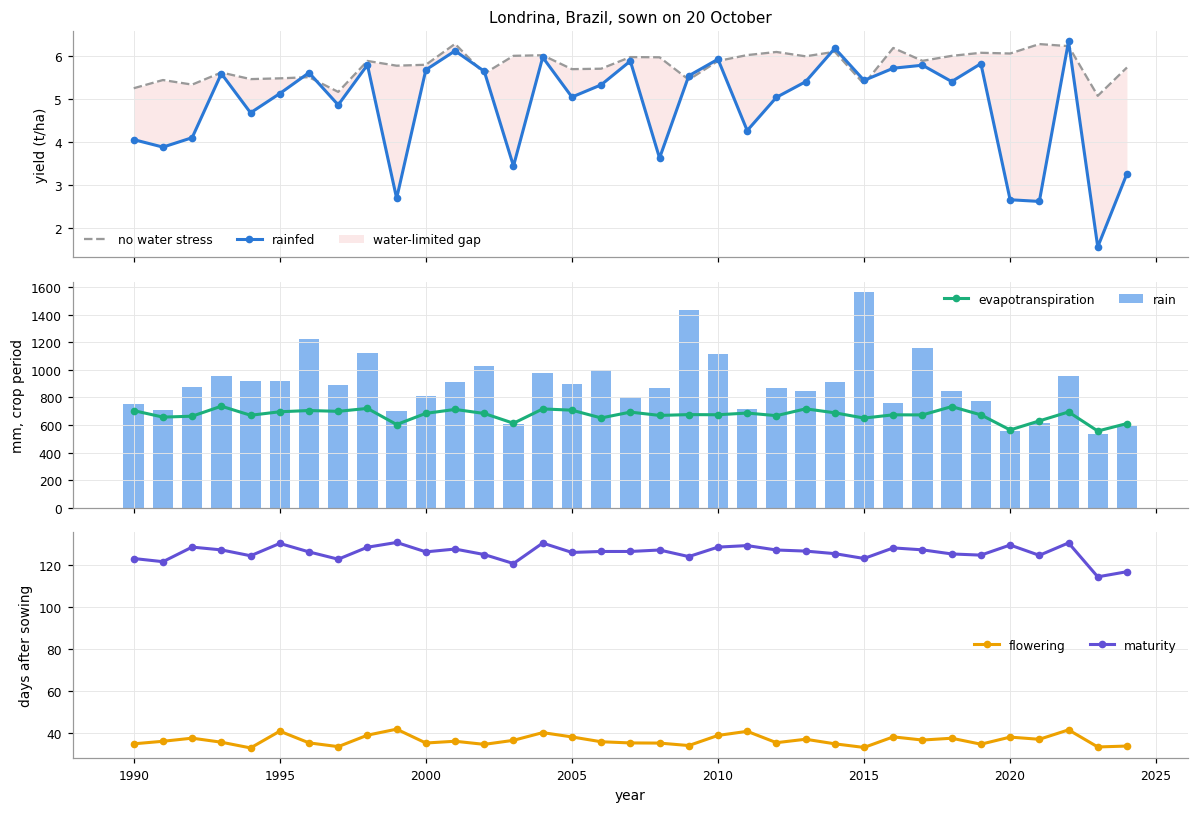

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
ax = axes[0]
ax.plot(o.index, o["yield_irrigated_t"], color="0.6", lw=1.5, ls="--", label="no water stress")
ax.plot(o.index, o["yield_t"], color="#2a78d6", lw=2, marker="o", markersize=4, label="rainfed")
ax.fill_between(o.index, o["yield_t"], o["yield_irrigated_t"], color="#e34948", alpha=0.12, lw=0, label="water-limited gap")
ax.set(ylabel="yield (t/ha)", title=f"{SITE}, sown on 20 October"); ax.legend(ncol=3)
ax = axes[1]
ax.bar(o.index, o[RAIN], color="#86b6ef", width=0.7, label="rain")
ax.plot(o.index, o[ET], color="#1baf7a", lw=2, marker="o", markersize=4, label="evapotranspiration")
ax.set(ylabel="mm, crop period"); ax.legend(ncol=2)
ax = axes[2]
ax.plot(o.index, o[FLO], color="#eda100", lw=2, marker="o", markersize=4, label="flowering")
ax.plot(o.index, o[MAT], color="#6250d6", lw=2, marker="o", markersize=4, label="maturity")
ax.set(ylabel="days after sowing", xlabel="year"); ax.legend(ncol=2)
fig.tight_layout(); plt.show()

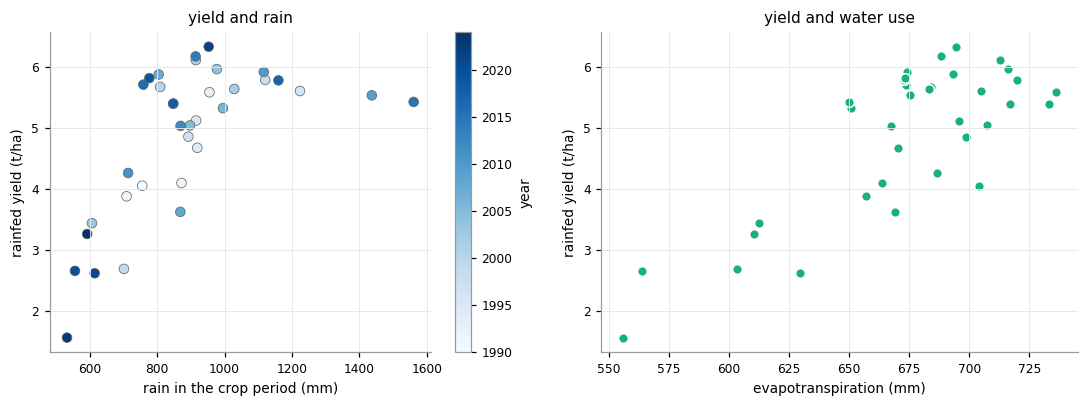

correlation yield-rain: 0.64, yield-ET: 0.79


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
sc = ax.scatter(o[RAIN], o["yield_t"], c=o.index, cmap="Blues", s=40, edgecolor="0.4", linewidth=0.5)
ax.set(xlabel="rain in the crop period (mm)", ylabel="rainfed yield (t/ha)", title="yield and rain")
plt.colorbar(sc, ax=ax, label="year")
ax = axes[1]
ax.scatter(o[ET], o["yield_t"], s=40, color="#1baf7a", edgecolor="white")
ax.set(xlabel="evapotranspiration (mm)", ylabel="rainfed yield (t/ha)", title="yield and water use")
fig.tight_layout(); plt.show()
print(f"correlation yield-rain: {o['yield_t'].corr(o[RAIN]):.2f}, yield-ET: {o['yield_t'].corr(o[ET]):.2f}")

## 5. The sowing window

All sowing dates from 1 September to 31 December, every 4 days, in every year 1990-2024: about
1,000 seasons in a few seconds. The heat map shows the rainfed yield of each year and date; the
curve below, its median and the 25-75 % band (the risk).

In [15]:
offsets = range(0, 122, 4)
grid = [(y, pd.Timestamp(y, 9, 1) + pd.Timedelta(days=d)) for y in YEARS for d in offsets]
t0 = time.time()
sw = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=[g[1] for g in grid], cultivar=cult)
print(f"{len(grid)} seasons in {time.time() - t0:.1f} s")
W = pd.DataFrame({"year": [g[0] for g in grid], "day": [g[1].strftime("%m-%d") for g in grid],
                  "yield": sw.outputs[YLD].to_numpy() * TO_T, "mat": sw.outputs[MAT].to_numpy(),
                  "rare": sw.rare_inputs.str.len().to_numpy() > 0})
H = W.pivot(index="year", columns="day", values="yield")

1085 seasons in 0.8 s


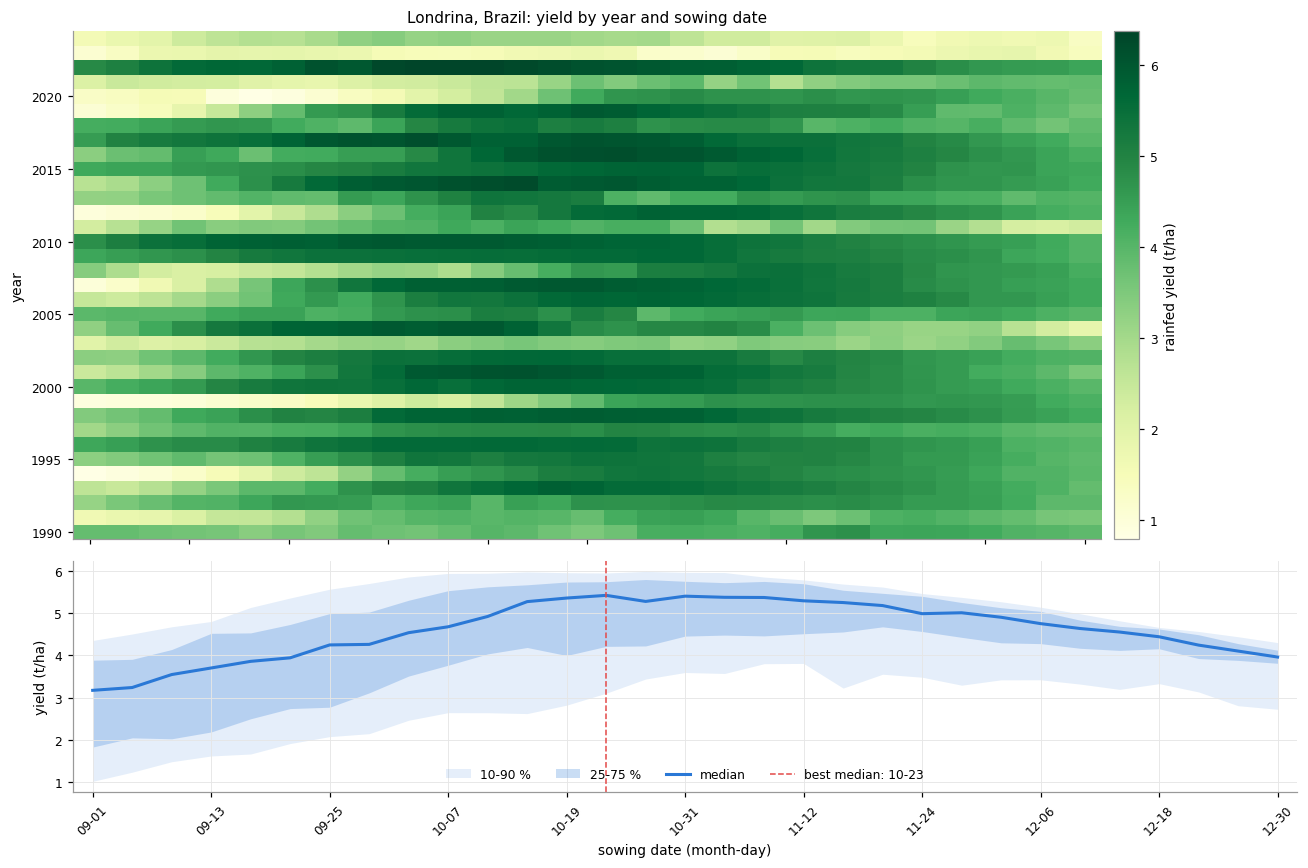

share of seasons with rare inputs: 10.0%


In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [2.2, 1]}, sharex=True)
ax = axes[0]
im = ax.imshow(H.to_numpy(), aspect="auto", cmap="YlGn", origin="lower",
               extent=(-0.5, H.shape[1] - 0.5, H.index[0] - 0.5, H.index[-1] + 0.5))
plt.colorbar(im, ax=ax, label="rainfed yield (t/ha)", pad=0.01)
ax.set(ylabel="year", title=f"{SITE}: yield by year and sowing date"); ax.grid(False)
q = H.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).T
x = np.arange(len(q))
ax = axes[1]
ax.fill_between(x, q[0.1], q[0.9], color="#2a78d6", alpha=0.12, lw=0, label="10-90 %")
ax.fill_between(x, q[0.25], q[0.75], color="#2a78d6", alpha=0.25, lw=0, label="25-75 %")
ax.plot(x, q[0.5], color="#2a78d6", lw=2, label="median")
best = int(np.argmax(q[0.5].to_numpy()))
ax.axvline(best, color="#e34948", lw=1, ls="--", label=f"best median: {q.index[best]}")
ax.set(ylabel="yield (t/ha)", xlabel="sowing date (month-day)"); ax.legend(ncol=4, loc="lower center")
ax.set_xticks(x[::3], q.index[::3], rotation=45)
fig.tight_layout(); plt.show()
print(f"share of seasons with rare inputs: {W['rare'].mean():.1%}")

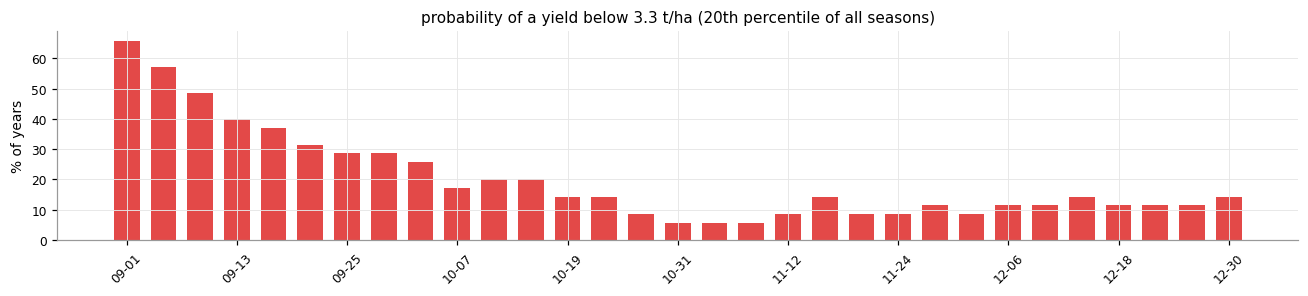

In [17]:
# risk: probability of a rainfed yield below a threshold, by sowing date
thr = float(np.nanpercentile(W["yield"], 20))
risk = (H < thr).mean()
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.bar(np.arange(len(risk)), risk * 100, color="#e34948", width=0.7)
ax.set_xticks(np.arange(len(risk))[::3], risk.index[::3], rotation=45)
ax.set(ylabel="% of years", title=f"probability of a yield below {thr:.1f} t/ha (20th percentile of all seasons)")
fig.tight_layout(); plt.show()

## 6. Cultivars

### 6.1 Maturity group

Maturity groups from 4.5 to 8.5 sown on the same date, 1990-2024. Later groups flower and mature
later (photoperiod), which changes the yield and its year-to-year variability.

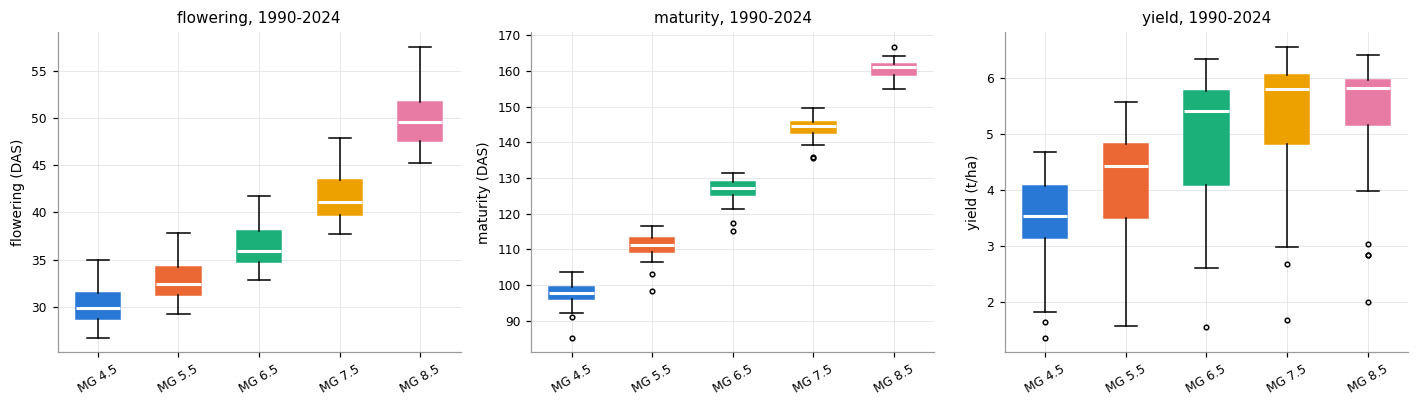

flowering       maturity       yield      
             mean   std     mean   std  mean   std
variant                                           
MG 4.5      30.24  2.23    97.62  3.61  3.47  0.86
MG 5.5      32.85  2.32   111.00  3.67  4.08  1.07
MG 6.5      36.45  2.47   126.51  3.62  4.87  1.22
MG 7.5      41.71  2.71   143.89  3.08  5.26  1.22
MG 8.5      49.90  3.13   160.59  2.33  5.29  1.13

In [18]:
variants = {f"MG {mg}": cultivar_for(mg) for mg in (4.5, 5.5, 6.5, 7.5, 8.5)}
rows = []
for name, cv in variants.items():
    r = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cv).outputs
    rows.append(pd.DataFrame({"variant": name, "year": YEARS, "yield": r[YLD].to_numpy() * TO_T,
                              "flowering": r[FLO].to_numpy(), "maturity": r[MAT].to_numpy()}))
V = pd.concat(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
names = list(variants)
for ax, col, lab in zip(axes, ("flowering", "maturity", "yield"), ("flowering (DAS)", "maturity (DAS)", "yield (t/ha)")):
    data = [V.loc[V["variant"] == n, col].dropna().to_numpy() for n in names]
    bp = ax.boxplot(data, tick_labels=names, widths=0.55, patch_artist=True,
                    medianprops=dict(color="white", lw=2), flierprops=dict(markersize=3))
    for patch, colr in zip(bp["boxes"], SERIES):
        patch.set(facecolor=colr, edgecolor=colr)
    ax.set(ylabel=lab, title=f"{lab.split(' (')[0]}, 1990-2024"); ax.tick_params(axis="x", labelrotation=30)
fig.tight_layout(); plt.show()
V.groupby("variant", sort=False)[["flowering", "maturity", "yield"]].agg(["mean", "std"]).round(2)

### 6.2 Parameter sensitivity

One parameter at a time across its training range, the others at their typical value; median and
25-75 % band over 1990-2024. The x-range is the 0.5-99.5 % range of the training data
(`card["domain"]`), so every point is inside the domain.

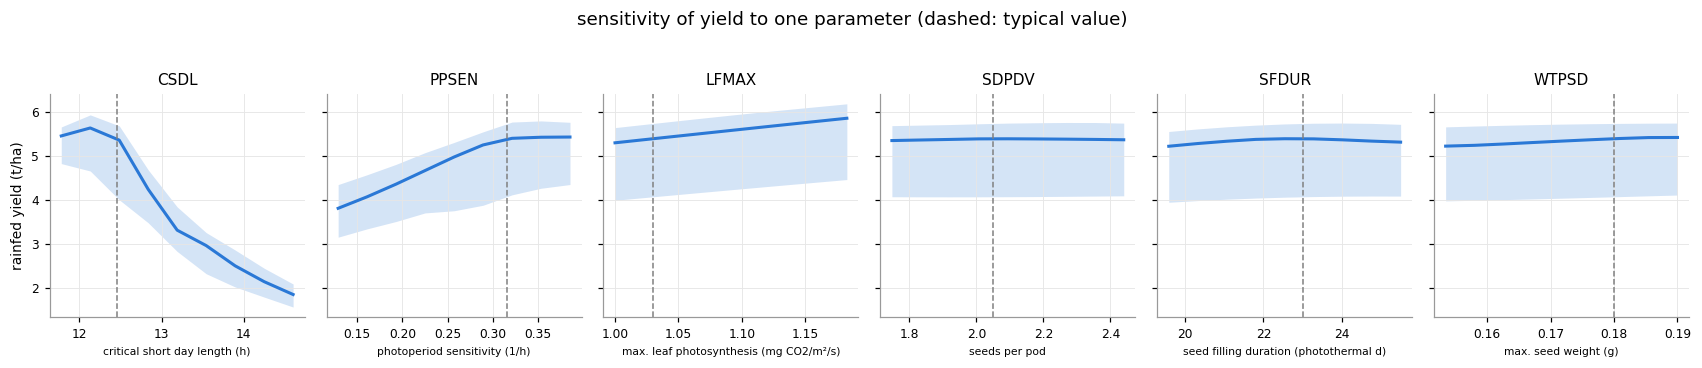

In [19]:
SENS = [('CSDL', 'critical short day length (h)'), ('PPSEN', 'photoperiod sensitivity (1/h)'), ('LFMAX', 'max. leaf photosynthesis (mg CO2/m²/s)'), ('SDPDV', 'seeds per pod'), ('SFDUR', 'seed filling duration (photothermal d)'), ('WTPSD', 'max. seed weight (g)')]
fig, axes = plt.subplots(1, len(SENS), figsize=(2.6 * len(SENS), 3.2), sharey=True)
for ax, (p, lab) in zip(axes, SENS):
    lo, hi = emu.card["domain"][p]["q005"], emu.card["domain"][p]["q995"]
    xs = np.linspace(lo, hi, 9)
    med, q1, q3 = [], [], []
    for v in xs:
        r = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar={**cult, p: v}).outputs[YLD] * TO_T
        med.append(r.median()); q1.append(r.quantile(0.25)); q3.append(r.quantile(0.75))
    ax.fill_between(xs, q1, q3, color="#2a78d6", alpha=0.2, lw=0)
    ax.plot(xs, med, color="#2a78d6", lw=2)
    ax.axvline(cult[p], color="0.5", lw=1, ls="--")
    ax.set(title=p, xlabel=lab); ax.xaxis.label.set_size(7)
axes[0].set_ylabel("rainfed yield (t/ha)")
fig.suptitle("sensitivity of yield to one parameter (dashed: typical value)", y=1.03)
fig.tight_layout(); plt.show()

## 7. Water: rainfed vs. no water stress

`irrigated=True` predicts the season without water stress (the water balance switched off, as in
the training seasons without water limitation). The difference is the water-limited yield gap.

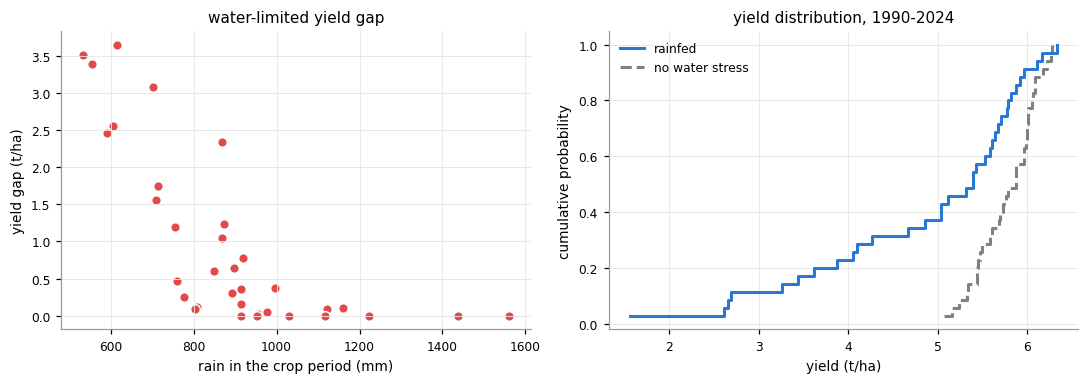

mean gap 0.94 t/ha (16% of the unstressed yield)


In [20]:
gap = (o["yield_irrigated_t"] - o["yield_t"]).clip(lower=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.scatter(o[RAIN], gap, s=40, color="#e34948", edgecolor="white")
ax.set(xlabel="rain in the crop period (mm)", ylabel="yield gap (t/ha)", title="water-limited yield gap")
ax = axes[1]
srt = np.sort(o["yield_t"]); srt_i = np.sort(o["yield_irrigated_t"])
p = np.arange(1, len(srt) + 1) / len(srt)
ax.step(srt, p, where="post", color="#2a78d6", lw=2, label="rainfed")
ax.step(srt_i, p, where="post", color="0.5", lw=2, ls="--", label="no water stress")
ax.set(xlabel="yield (t/ha)", ylabel="cumulative probability", title="yield distribution, 1990-2024"); ax.legend()
fig.tight_layout(); plt.show()
print(f"mean gap {gap.mean():.2f} t/ha ({gap.mean() / o['yield_irrigated_t'].mean():.0%} of the unstressed yield)")

## 8. Climate scenarios

The training seasons included perturbations: +-1 to +4 °C on Tmax and Tmin, rain x0.7-1.3 and CO₂
350-800 ppm. The same perturbations can be applied to the observed weather of the site
(`dt`, `rain_factor`, `co2`), which gives a quick climate-sensitivity analysis. The values are
changes of the mean yield 1990-2024 relative to the baseline (observed weather, Mauna Loa CO₂).

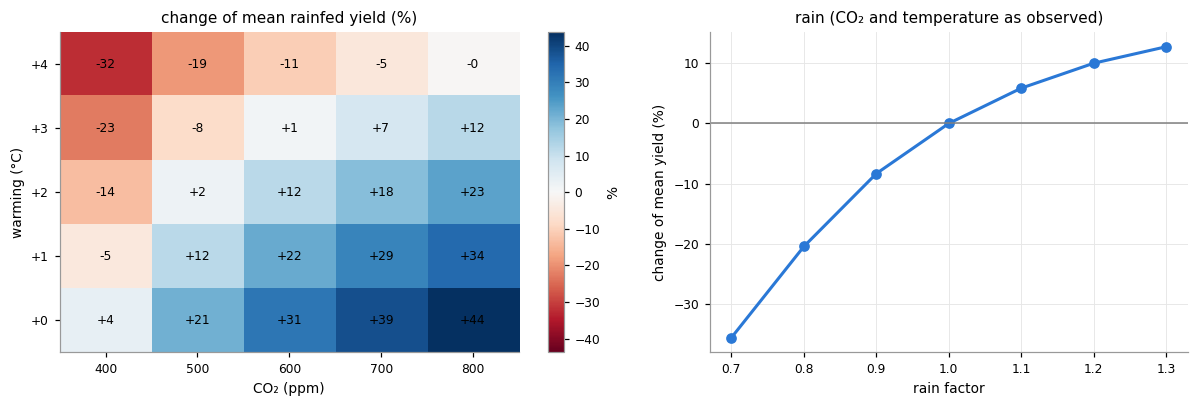

In [21]:
base = o["yield_t"].mean()
DTS, CO2S = [0, 1, 2, 3, 4], [400, 500, 600, 700, 800]
G = pd.DataFrame(index=DTS, columns=CO2S, dtype=float)
for dt in DTS:
    for co2 in CO2S:
        y = emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cult, dt=dt, co2=co2).outputs[YLD]
        G.loc[dt, co2] = 100 * (y.mean() * TO_T / base - 1)
RF = [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]
rf = [100 * (emu.predict(weather, lat=LAT, elev=ELEV, soil=soil, sowing=dates, cultivar=cult, rain_factor=f)
             .outputs[YLD].mean() * TO_T / base - 1) for f in RF]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
lim = np.nanmax(np.abs(G.to_numpy()))
im = ax.imshow(G.to_numpy(float), cmap="RdBu", vmin=-lim, vmax=lim, origin="lower", aspect="auto")
for i, dt in enumerate(DTS):
    for j, co2 in enumerate(CO2S):
        ax.text(j, i, f"{G.loc[dt, co2]:+.0f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(CO2S)), CO2S); ax.set_yticks(range(len(DTS)), [f"+{d}" for d in DTS])
ax.set(xlabel="CO₂ (ppm)", ylabel="warming (°C)", title="change of mean rainfed yield (%)"); ax.grid(False)
plt.colorbar(im, ax=ax, label="%")
ax = axes[1]
ax.plot(RF, rf, color="#2a78d6", lw=2, marker="o")
ax.axhline(0, color="0.5", lw=1)
ax.set(xlabel="rain factor", ylabel="change of mean yield (%)", title="rain (CO₂ and temperature as observed)")
fig.tight_layout(); plt.show()

## 9. A regional map

A 2° grid over the soybean area of southern and central Brazil. For each point: weather and soil
are downloaded (once; cached), the typical cultivar of the latitude is sown every 5 days from
15 September to 15 December in 2000-2024, and the median yield and the best sowing date are
mapped. Points without soil data (water, cities) are skipped.

In [22]:
lats = np.arange(-30.5, -11.4, 2.0)
lons = np.arange(-57.5, -44.4, 2.0)
pts = pd.DataFrame([(f"p{i}_{j}", la, lo) for i, la in enumerate(lats) for j, lo in enumerate(lons)],
                   columns=["id", "lat", "lon"])
t0 = time.time()
soils = soilgrids.fetch_many(pts, n_jobs=16)
YEARS_MAP = range(2000, 2025)
OFFS = range(0, 92, 5)
rows = []
for p in pts.itertuples():
    s = soils[p.id]
    if s[["clay", "sand", "soc", "bdod"]].isna().any().any():
        continue
    w = fill_gaps(fetch(p.lat, p.lon, "1999-01-01", "2025-12-31"))
    if EMU_FAMILY == "dssat":
        cv = emu.cultivar(lat=p.lat)
    else:
        cv = emu.cultivar(lat=p.lat, mg=emu.typical_mg(p.lat), weather=w, sowing="2020-11-01", cycle_days=CYCLE_DAYS)
    ds = [pd.Timestamp(y, 9, 15) + pd.Timedelta(days=d) for y in YEARS_MAP for d in OFFS]
    r = emu.predict(w, lat=p.lat, elev=w.attrs.get("elev"), soil=s, sowing=ds, cultivar=cv)
    t = pd.DataFrame({"off": [d for _ in YEARS_MAP for d in OFFS], "y": r.outputs[YLD].to_numpy() * TO_T})
    med = t.groupby("off")["y"].median()
    rows.append({"lat": p.lat, "lon": p.lon, "median_yield": med.max(), "best_day": int(med.idxmax()),
                 "cv": t.groupby("off")["y"].std().loc[med.idxmax()] / med.max(),
                 "rare": float((r.rare_inputs.str.len() > 0).mean()), "out": float((r.out_of_domain.str.len() > 0).mean())})
M = pd.DataFrame(rows)
print(f"{len(M)} points, {len(M) * len(YEARS_MAP) * len(OFFS)} seasons, {time.time() - t0:.0f} s (with downloads)")

62 points, 29450 seasons, 26 s (with downloads)


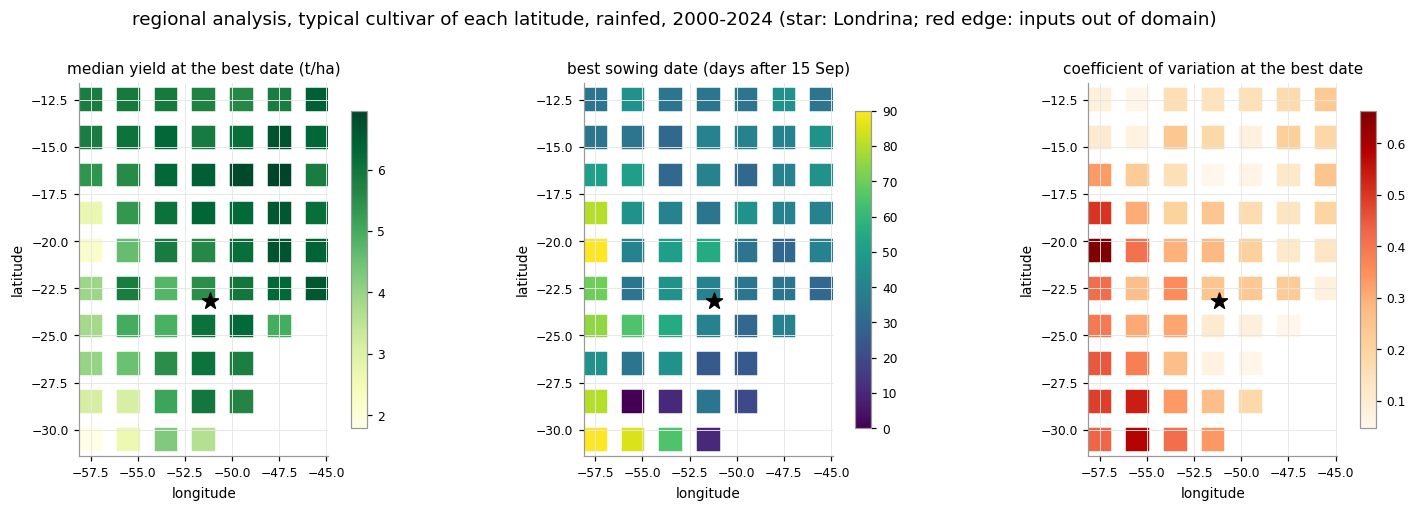

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
specs = [("median_yield", "YlGn", "median yield at the best date (t/ha)"),
         ("best_day", "viridis", "best sowing date (days after 15 Sep)"),
         ("cv", "OrRd", "coefficient of variation at the best date")]
for ax, (col, cmap, title) in zip(axes, specs):
    sc = ax.scatter(M["lon"], M["lat"], c=M[col], cmap=cmap, s=260, marker="s", edgecolor="white", linewidth=1)
    bad = M[M["out"] > 0]
    ax.scatter(bad["lon"], bad["lat"], s=260, marker="s", facecolor="none", edgecolor="#e34948", linewidth=1.5)
    ax.scatter([LON], [LAT], marker="*", s=120, color="k")
    plt.colorbar(sc, ax=ax, shrink=0.85)
    ax.set(title=title, xlabel="longitude", ylabel="latitude", aspect="equal")
fig.suptitle("regional analysis, typical cultivar of each latitude, rainfed, 2000-2024 (star: Londrina; red edge: inputs out of domain)", y=1.0)
fig.tight_layout(); plt.show()

## 10. Speed

In [24]:
X = sw.inputs
big = pd.concat([X] * 100, ignore_index=True)
t0 = time.time(); emu.predict_inputs(big); t_net = time.time() - t0
t0 = time.time(); emu.inputs(weather, lat=LAT, elev=ELEV, soil=soil, sowing=[g[1] for g in grid], cultivar=cult); t_in = time.time() - t0
print(f"network: {1e6 * t_net / len(big):.1f} µs per season ({len(big)} seasons in {t_net:.2f} s)")
print(f"inputs from daily weather: {1e3 * t_in / len(grid):.2f} ms per season")
print("the crop model itself takes ~0.1-1 s per season (plus writing and reading its files)")

network: 15.7 µs per season (108500 seasons in 1.71 s)
inputs from daily weather: 0.72 ms per season
the crop model itself takes ~0.1-1 s per season (plus writing and reading its files)


## 11. Your own data

Everything above used NASA POWER weather and SoilGrids soil, as in training. The library also runs
on **your own data**: a weather station, a measured soil profile, a cultivar calibrated for the
crop model, the treatments of a field trial. This section shows each step with published field
trials of the DSSAT example data ([dssat-csm-data](https://github.com/DSSAT/dssat-csm-data), files
downloaded from the public repository at a fixed commit, not redistributed here):

| trial | site | season | cultivars | treatments | observed |
|---|---|---|---|---|---|
| `UFGA7801` | Gainesville, Florida, USA (29.6° N) | 1978 | Bragg | irrigated, rainfed | yield, flowering, maturity |
| `IUAM8801`, `IUAM9001` | Ames, Iowa, USA (42.0° N) | 1988, 1990 | Williams-82, Elgin-87 | rainfed | yield, flowering, maturity |
| `PARA1801` | Paragominas, Pará, Brazil (3.4° S) | 2018 (calibration), 2019 (evaluation) | MG 7.7, MG 8.8 | 4 sowing dates, 10-40 plants/m², rainfed | yield, flowering, maturity |
| `LQBR1905` (Piracicaba only) | Piracicaba, São Paulo, Brazil (22.7° S) | 2017-2019 | M 7062 | rainfed, irrigated | yield |

They are used **only to show how**: the same calls work with any station, profile or trial.

1. station weather: read, check, compare with NASA POWER, complete the missing days;
2. measured soil: read, compare with the water retention used in training, complete missing properties;
3. the cultivar of the trial and the training domain;
4. emulator vs. observations;
5. calibration with the emulator (thousands of seasons per second);
6. export the results.

In [25]:
import os, urllib.request
from pathlib import Path
from cropemu.io import read_wth, read_sol, read_cul, read_experiment, read_observed
from cropemu.weather import check, fill_from
from cropemu.soil import fill_from as soil_fill_from
from cropemu.features import co2_at

DSSAT_DATA = "https://raw.githubusercontent.com/DSSAT/dssat-csm-data/99c95b340acb9515c2d0a8ab582f5fbbf076f345"
DSSAT_CUL = ("https://raw.githubusercontent.com/DSSAT/dssat-csm-os/25c93b9a2f73f8ec45bf441b198dac5fb7b22849"
             "/Data/Genotype/SBGRO048.CUL")
FILES = Path(os.environ.get("CROPEMU_CACHE", Path.home() / ".cache" / "cropemu")) / "dssat-example-data"

def get(rel, url=None):
    """Download a file of the DSSAT example data once (cached) and return its local path."""
    p = FILES / rel
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url or f"{DSSAT_DATA}/{rel}", p)
    return p

# sites of the trials: weather files, soil profile and coordinates
SITES = {
    "UFGA": dict(name="Gainesville", lat=29.63, lon=-82.37, elev=10, weather=["UFGA7801"],
                 soil=("SOIL", "IBSB910015")),
    "IUAM": dict(name="Ames", lat=42.00, lon=-93.50, elev=290, weather=["IUAM8801", "IUAM9001"],
                 soil=("SOIL", "IBSB910049")),
    "PARA": dict(name="Paragominas", lat=-3.383, lon=-47.417, elev=176, weather=["PARA1801", "PARA1901"],
                 soil=("BR", "BRPA080004")),
    "PIR2": dict(name="Piracicaba", lat=-22.725, lon=-47.648, elev=524,
                 weather=["PIR21701", "PIR21801", "PIR21901", "PIR22001"], soil=("BR", "BRNITOSSO3")),
}
TRIALS = ["UFGA7801", "IUAM8801", "IUAM9001", "PARA1801", "LQBR1905"]
for t in TRIALS:
    get(f"Soybean/{t}.SBX"); get(f"Soybean/{t}.SBA")
CUL = get("SBGRO048.CUL", DSSAT_CUL)
print(len([p for p in FILES.rglob("*") if p.is_file()]), "files of the DSSAT example data (downloaded once, cached)")

22 files of the DSSAT example data (downloaded once, cached)


### 11.1 Station weather

`cropemu.io.read_wth` reads DSSAT weather files (one or several years) into the standard daily table:
`srad`, `tmax`, `tmin`, `rain` and, when the station has them, `dewp`, `rhum` and `wind` (converted
to m/s at 2 m). Missing humidity is handled day by day (dew point, else relative humidity, else
Tmin), and missing wind is taken as 2 m/s in the reference evapotranspiration (FAO-56).

Any other station works the same way: a `DataFrame` indexed by date with these column names, and
the site in `attrs`. `check` reports missing days (here, between the files of different years),
missing values and values out of range:

```python
w = pd.read_csv("my_station.csv", index_col="date", parse_dates=True)
w = w.rename(columns={"radiation": "srad", "t_max": "tmax", "t_min": "tmin", "precip": "rain"})
w.attrs = {"lat": -23.3, "lon": -51.2, "elev": 560}
```

Always check the header: in these files the longitude of the Piracicaba station is written as
+47.6 (east) instead of -47.6, which is why the coordinates of each site are set above.

In [26]:
stations = {}
for sid, s in SITES.items():
    w = read_wth(*[get(f"Weather/{f}.WTH") for f in s["weather"]])
    if "wind" in w and (w["wind"].fillna(0) == 0).all():        # a column of zeros is a missing sensor
        w = w.drop(columns="wind")
    stations[sid] = w
    print(f"{s['name']:12s} {w.index.min():%Y-%m-%d} to {w.index.max():%Y-%m-%d}  columns: {list(w.columns)}  "
          f"file lat/lon: {w.attrs['lat']}, {w.attrs['lon']}  missing days: {check(w)['missing_days']}")

Gainesville  1978-01-01 to 1978-12-31  columns: ['srad', 'tmax', 'tmin', 'rain']  file lat/lon: 29.63, -82.37  missing days: 0
Ames         1988-05-01 to 1990-10-07  columns: ['srad', 'tmax', 'tmin', 'rain', 'dewp', 'wind']  file lat/lon: 42.0, -93.5  missing days: 567
Paragominas  2018-01-01 to 2019-06-30  columns: ['srad', 'tmax', 'tmin', 'rain']  file lat/lon: -3.383, -47.417  missing days: 176
Piracicaba   2017-01-01 to 2020-12-30  columns: ['srad', 'tmax', 'tmin', 'rain', 'dewp', 'wind']  file lat/lon: -22.725, 47.648  missing days: 0


**Station vs. NASA POWER.** The emulator was trained with NASA POWER; a station is usually more
accurate locally, but check how much the two differ before mixing them. At Paragominas (2018-2019):

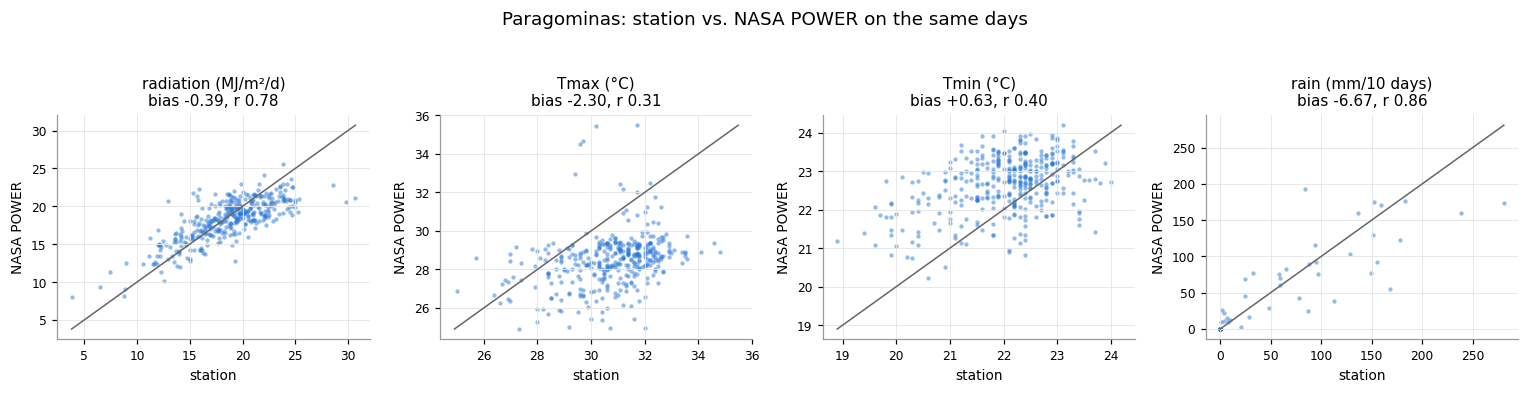

In [27]:
st = stations["PARA"]
power = fill_gaps(fetch(SITES["PARA"]["lat"], SITES["PARA"]["lon"], "2017-11-01", "2019-12-31"))
both = st[["srad", "tmax", "tmin", "rain"]].join(power[["srad", "tmax", "tmin", "rain"]], rsuffix="_power").dropna()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (v, lab) in zip(axes, [("srad", "radiation (MJ/m²/d)"), ("tmax", "Tmax (°C)"), ("tmin", "Tmin (°C)"),
                               ("rain", "rain (mm/10 days)")]):
    a, b = both[v], both[v + "_power"]
    if v == "rain":                                   # daily rain is too noisy: 10-day totals
        a, b = a.resample("10D").sum(), b.resample("10D").sum()
    ax.scatter(a, b, s=8, alpha=0.5, color=SERIES[0], lw=0)
    lim = [min(a.min(), b.min()), max(a.max(), b.max())]
    ax.plot(lim, lim, color="0.4", lw=1)
    ax.set(xlabel="station", ylabel="NASA POWER", title=f"{lab}\nbias {(b - a).mean():+.2f}, r {np.corrcoef(a, b)[0, 1]:.2f}")
fig.suptitle("Paragominas: station vs. NASA POWER on the same days", y=1.04)
fig.tight_layout(); plt.show()

**Completing the station.** A season needs weather from 30 days before sowing to at least 130 days
after (more for the AquaCrop thermal time). The Paragominas file starts on 1 January 2018, a week
before the first sowing: `fill_from` takes the missing days (and missing columns, such as humidity)
from NASA POWER and records how many values it took.

{'source': 'NASA POWER', 'srad': 26, 'tmax': 26, 'tmin': 26, 'rain': 26, 'rhum': 182, 'wind': 182, 'dewp': 182}


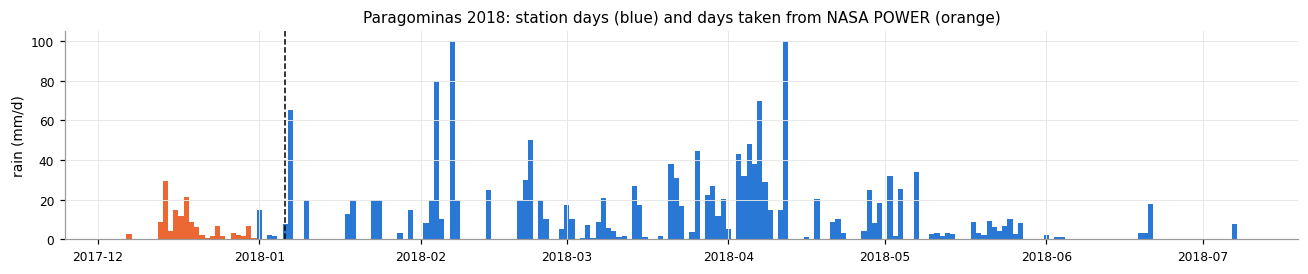

In [28]:
def season_weather(sid, sowing, after=150):
    """Station weather of a season, completed with NASA POWER where the station has no data."""
    s, w = SITES[sid], stations[sid]
    start, end = pd.Timestamp(sowing) - pd.Timedelta(days=31), pd.Timestamp(sowing) + pd.Timedelta(days=after)
    if w.reindex(pd.date_range(start, end))[["srad", "tmax", "tmin", "rain"]].notna().all().all():
        return w
    if start.year < 1984:                               # NASA POWER starts in 1984
        raise ValueError(f"{s['name']}: the station does not cover {start:%Y-%m-%d} to {end:%Y-%m-%d}")
    return fill_from(w, fill_gaps(fetch(s["lat"], s["lon"], start.date(), end.date())))

w = season_weather("PARA", "2018-01-06")
print(w.attrs["filled_from"])
fig, ax = plt.subplots(figsize=(12, 2.6))
win = w.loc["2017-12-01":"2018-07-31"]
src = stations["PARA"].reindex(win.index)["tmax"].notna()
ax.bar(win.index, win["rain"], color=np.where(src, "#2a78d6", "#eb6834"), width=1)
ax.set(ylabel="rain (mm/d)", title="Paragominas 2018: station days (blue) and days taken from NASA POWER (orange)")
ax.axvline(pd.Timestamp("2018-01-06"), color="k", lw=1, ls="--")
fig.tight_layout(); plt.show()

### 11.2 Measured soil

`cropemu.io.read_sol` reads a profile of a DSSAT soil file with its **measured water limits**
(`ll`, `dul`, `sat`). The emulator uses them as they are; it only computes the water retention
(with the method used in training) when they are missing. Profiles deeper than 2 m are cut at
2 m, the depth of every training profile (`emu.training_soil`).

Missing properties can be taken from SoilGrids at the same point with `cropemu.soil.fill_from`:
the Ames profile has water limits but no texture or organic carbon (0 in the file).

Ames: taken from SoilGrids: {'source': 'SoilGrids 2.0 (1 km)', 'clay': 12, 'sand': 12, 'silt': 12, 'soc': 12}


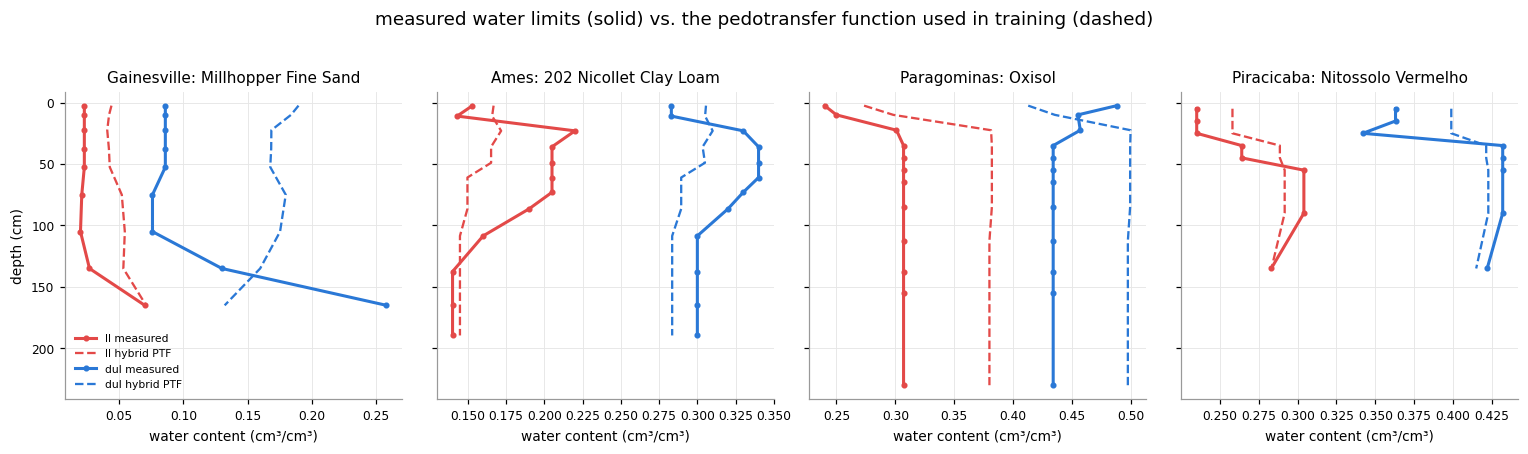

,profile,clay 0-30 cm (%),PAW measured (mm),PAW from PTF (mm)
site,,,,
Gainesville,Millhopper Fine Sand,2.1,158.4,203.0
Ames,202 NICOLLET CLAY LOAM,25.0,286.1,277.9
Paragominas,Oxisol,79.7,272.2,238.1
Piracicaba,NITOSSOLO VERMELHO! SOLO PIRACICABA ORIGINAL,46.2,201.2,200.1


In [29]:
soils = {}
for sid, s in SITES.items():
    f, pid = s["soil"]
    p = read_sol(get(f"Soil/{f}.SOL"), pid)
    p.loc[p["soc"] <= 0, "soc"] = np.nan                    # 0 % organic carbon: not measured
    if p[["clay", "sand", "soc", "bdod"]].isna().any().any():
        p = soil_fill_from(p, soilgrids.fetch(s["lat"], s["lon"]), ["clay", "sand", "silt", "soc", "bdod"])
        print(f"{s['name']}: taken from SoilGrids: {p.attrs['filled_from']}")
    soils[sid] = p
show = ["UFGA", "IUAM", "PARA", "PIR2"]
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
rows = []
for ax, sid in zip(axes, show):
    m = soils[sid]
    ptf = hydraulics(m.drop(columns=["ll", "dul", "sat", "ksat"]), method=emu.card["hydraulics"], lat=SITES[sid]["lat"])
    mid = (m["top"] + m["bottom"]) / 2
    for col, colr in (("ll", "#e34948"), ("dul", "#2a78d6")):
        ax.plot(m[col], mid, color=colr, lw=2, marker="o", ms=3, label=f"{col} measured")
        ax.plot(ptf[col], mid, color=colr, lw=1.5, ls="--", label=f"{col} {emu.card['hydraulics']} PTF")
    ax.invert_yaxis() if sid == show[0] else None
    paw = lambda d: float(((d["dul"] - d["ll"]) * (d["bottom"].clip(upper=200) - d["top"]).clip(lower=0) * 10).sum())
    rows.append({"site": SITES[sid]["name"], "profile": m.attrs["name"], "clay 0-30 cm (%)": m.loc[m["top"] < 30, "clay"].mean(),
                 "PAW measured (mm)": paw(m), "PAW from PTF (mm)": paw(ptf)})
    ax.set(title=f"{SITES[sid]['name']}: {m.attrs['name'].split('!')[0][:24].title()}", xlabel="water content (cm³/cm³)")
axes[0].set_ylabel("depth (cm)"); axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("measured water limits (solid) vs. the pedotransfer function used in training (dashed)", y=1.02)
fig.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("site").round(1)

The measured and estimated limits can differ a lot (e.g. the sandy Millhopper profile of
Gainesville, or the very clayey Oxisol of Paragominas). Use the measured profile when you have it;
the emulator then shows if the soil falls outside the training data (`out_of_domain`).

### 11.3 The cultivar of the trial

`cropemu.io.read_cul` reads the coefficients of a DSSAT cultivar, and `emu.cultivar_from_dssat`
turns them into the emulator cultivar. The emulator also takes the maturity group (MG): taken from
the cultivar name when it states it (MG77PA, MG88PA), otherwise estimated from the critical day
length CSDL (`emu.mg_from_csdl`, the inverse of the default coefficients).

**Training domain.** The emulator was trained with coefficients varying around the defaults of each
MG. Cultivars calibrated in a study often fall outside that range; `emu.cultivar_domain` shows where
each coefficient sits (0 = training minimum, 1 = maximum).

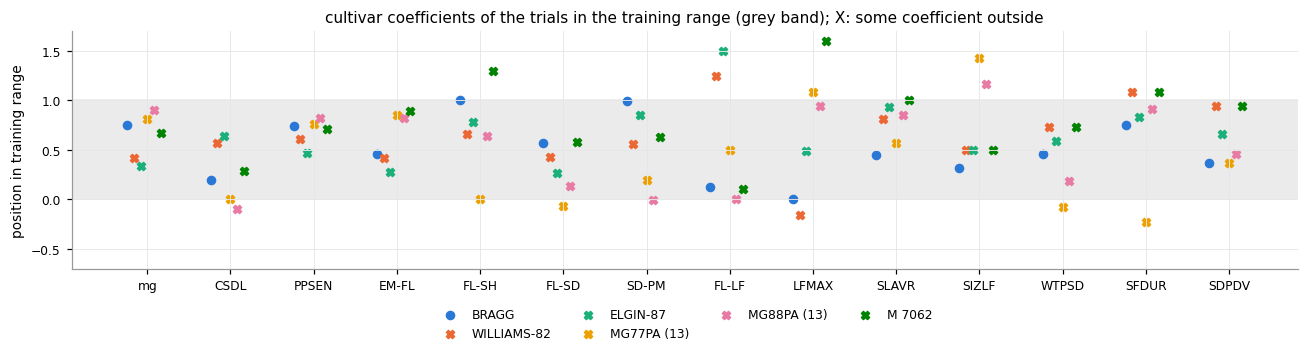

value      min      max         status
cultivar    parameter                                         
WILLIAMS-82 FL-LF       28.00   18.000   26.000  out of domain
            LFMAX        0.97    1.000    1.184  out of domain
            SFDUR       26.00   19.550   25.500  out of domain
ELGIN-87    FL-LF       30.00   18.000   26.000  out of domain
MG77PA (13) FL-SD       10.50   11.000   18.400  out of domain
            LFMAX        1.20    1.000    1.184  out of domain
            SIZLF      230.00  153.000  207.000  out of domain
            WTPSD        0.15    0.153    0.190  out of domain
            SFDUR       18.20   19.550   25.500  out of domain
MG88PA (13) CSDL        11.50   11.780   14.600  out of domain
            SD-PM       25.00   25.077   37.700  out of domain
            SIZLF      216.00  153.000  207.000  out of domain
M 7062      FL-SH       11.50    5.000   10.000  out of domain
            LFMAX        1.30    1.000    1.184  out of domain
            SFDUR       26.00   19.550   25.500  out of domain

In [30]:
MG_IN_NAME = {"RB0002": 7.7, "RB0003": 8.8}            # MG77PA and MG88PA
def load_trial(t):
    # treatments (only those at the sites above) and observations of a trial
    x = read_experiment(FILES / f"Soybean/{t}.SBX")
    return x[x["WSTA"].isin(SITES)], read_observed(FILES / f"Soybean/{t}.SBA")

trials = {t: load_trial(t) for t in TRIALS}
cultivars = {}
for t, (x, _) in trials.items():
    for ing, name in x[["INGENO", "CNAME"]].drop_duplicates().itertuples(index=False):
        coef = read_cul(CUL, ing)
        cultivars[name.strip()] = emu.cultivar_from_dssat(coef, mg=MG_IN_NAME.get(ing))
dom = pd.concat({n: emu.cultivar_domain(c) for n, c in cultivars.items()}, names=["cultivar"])
pos = dom["position"].unstack()
fig, ax = plt.subplots(figsize=(12, 3.4))
for i, (name, r) in enumerate(pos.iterrows()):
    x = np.arange(len(r))
    ax.scatter(x + (i - len(pos) / 2) * 0.08, r.clip(-0.6, 1.6), s=28, label=name,
               marker="o" if r.between(0, 1).all() else "X")
ax.axhspan(0, 1, color="0.92", zorder=0)
ax.set_xticks(np.arange(pos.shape[1]), pos.columns, rotation=0)
ax.set(ylabel="position in training range", ylim=(-0.7, 1.7),
       title="cultivar coefficients of the trials in the training range (grey band); X: some coefficient outside")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); plt.show()
dom[dom["status"] != "ok"][["value", "min", "max", "status"]].round(3)

### 11.4 Emulator vs. observations

Every treatment is predicted with its station weather (completed with NASA POWER), its measured
soil, its cultivar, its sowing date and its water regime (`irrigated=True` means no water stress:
the trials with limited irrigation are not exactly that). CO₂ follows the Mauna Loa record, with
the 1978 value (335 ppm) raised to the training minimum (345 ppm).

What the emulator does **not** know: plant density and row spacing (fixed at 30 plants/m² and
50 cm in training), nitrogen, pests and diseases. The comparison mixes the error of the emulator
(validation: ~450 kg/ha and ~3 days) with the error of the crop model itself, which was not
calibrated for these sites.

In [31]:
CO2_MIN = emu.card["domain"]["co2"]["min"]
das = lambda d: np.nan if d is None or pd.isna(d) else (d - r["sowing"]).days
rows = []
for t, (x, obs) in trials.items():
    for trno, r in x.iterrows():
        sid, o = r["WSTA"], (obs.loc[trno] if trno in obs.index else pd.Series(dtype=float))
        s = SITES[sid]
        w = season_weather(sid, r["sowing"])
        cv = cultivars[r["CNAME"].strip()]
        co2 = max(co2_at(r["sowing"] + pd.Timedelta(days=60)), CO2_MIN)
        p = emu.predict(w, lat=s["lat"], elev=s["elev"], soil=soils[sid], sowing=r["sowing"], cultivar=cv,
                        irrigated=r["irrigated"], co2=co2)
        rows.append({"trial": t, "trno": trno, "site": s["name"], "cultivar": r["CNAME"].strip(),
                     "sowing": r["sowing"], "plants_m2": r["plants_m2"], "irrigated": r["irrigated"],
                     "obs_yield": o.get("HWAM", np.nan), "obs_anthesis": das(o.get("ADAT")), "obs_maturity": das(o.get("MDAT")), "yield": p.outputs["HWAM"].iloc[0], "anthesis": p.outputs["ADAT_dap"].iloc[0], "maturity": p.outputs["MDAT_dap"].iloc[0],
                     "out_of_domain": ", ".join(p.out_of_domain.iloc[0])})
field = pd.DataFrame(rows)
field.head(8).round(1)

,trial,trno,site,cultivar,sowing,plants_m2,irrigated,obs_yield,obs_anthesis,obs_maturity,yield,anthesis,maturity,out_of_domain
0,UFGA7801,1,Gainesville,BRAGG,1978-06-15,29.9,True,3041.0,45.0,116.0,4450.2,43.1,117.4,"paw30_mm, clay30, sand30"
1,UFGA7801,2,Gainesville,BRAGG,1978-06-15,29.9,False,1178.0,45.0,116.0,1110.3,43.8,108.2,"paw30_mm, clay30, sand30"
2,IUAM8801,1,Ames,WILLIAMS-82,1988-05-11,27.2,False,2368.0,51.0,129.0,1806.7,61.2,127.8,"FL-LF, LFMAX, SFDUR"
3,IUAM8801,2,Ames,ELGIN-87,1988-05-11,28.5,False,2372.0,43.0,107.0,1543.7,47.5,116.3,FL-LF
4,IUAM9001,1,Ames,WILLIAMS-82,1990-05-08,19.2,False,3168.0,66.0,139.0,4145.4,66.6,133.5,"FL-LF, LFMAX, SFDUR"
5,IUAM9001,2,Ames,ELGIN-87,1990-05-08,19.6,False,3534.0,52.0,126.0,4051.8,55.4,124.4,FL-LF
6,PARA1801,1,Paragominas,MG77PA (13),2018-01-06,10.0,False,3102.0,35.0,87.0,4251.7,36.6,91.1,"clay30, FL-SD, LFMAX, SIZLF, WTPSD, SFDUR"
7,PARA1801,2,Paragominas,MG77PA (13),2018-01-06,20.0,False,3614.0,35.0,87.0,4251.7,36.6,91.1,"clay30, FL-SD, LFMAX, SIZLF, WTPSD, SFDUR"


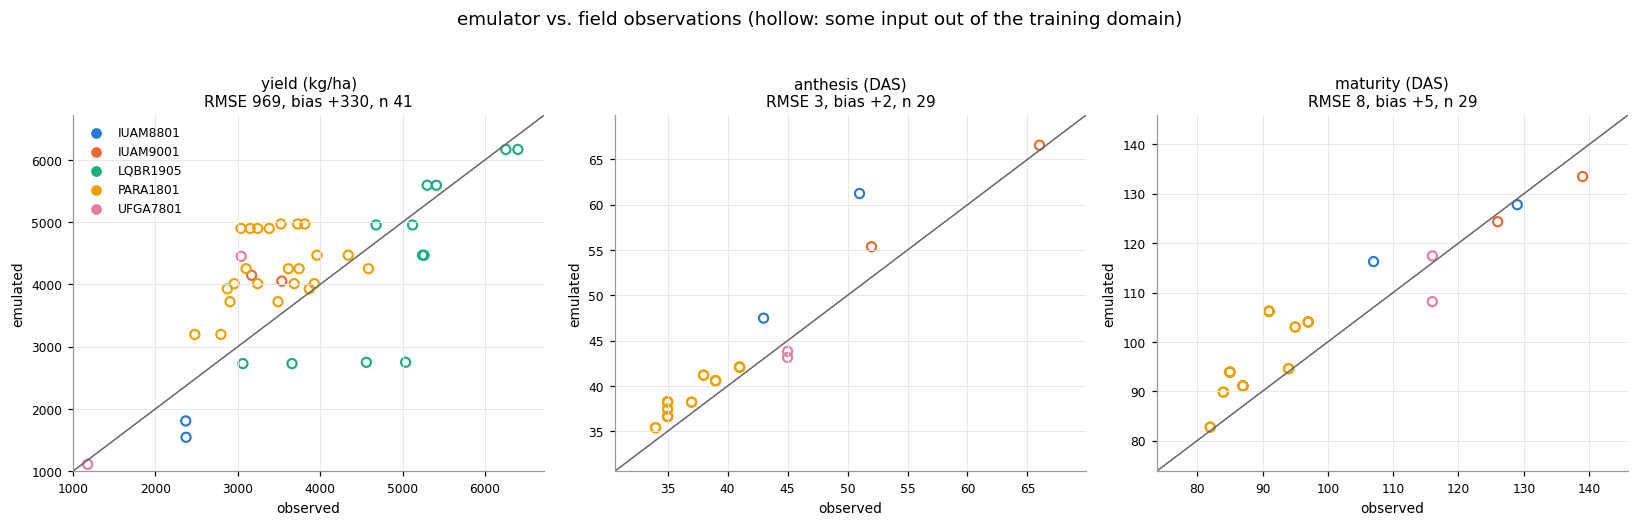

yield                     anthesis                maturity            \
             n    RMSE   bias    r        n RMSE bias    r        n RMSE bias   
trial                                                                           
IUAM8801   2.0   707.5 -694.8  NaN      2.0  7.9  7.4  NaN      2.0  6.6  4.0   
IUAM9001   2.0   782.1  747.6  NaN      2.0  2.4  2.0  NaN      2.0  4.1 -3.6   
LQBR1905  12.0   957.6 -555.3  0.8      0.0  NaN  NaN  NaN      0.0  NaN  NaN   
PARA1801  23.0  1005.2  814.9  0.4     23.0  2.1  2.0  0.9     23.0  8.5  7.1   
UFGA7801   2.0   997.6  670.8  NaN      2.0  1.6 -1.5  NaN      2.0  5.6 -3.2   

               
            r  
trial          
IUAM8801  NaN  
IUAM9001  NaN  
LQBR1905  NaN  
PARA1801  0.8  
UFGA7801  NaN

In [32]:
def scores(d, a, b):
    d = d[[a, b]].dropna()
    e = d[b] - d[a]
    return pd.Series({"n": len(d), "RMSE": np.sqrt((e ** 2).mean()), "bias": e.mean(),
                      "r": d[a].corr(d[b]) if len(d) > 2 else np.nan})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
groups = list(field.groupby("trial"))
for ax, (v, lab) in zip(axes, [("yield", 'yield (kg/ha)')] + [('anthesis', 'anthesis (DAS)'), ('maturity', 'maturity (DAS)')]):
    for i, (t, d) in enumerate(groups):
        d = d.dropna(subset=["obs_" + v])
        ood = d["out_of_domain"] != ""
        ax.scatter(d.loc[~ood, "obs_" + v], d.loc[~ood, v], color=SERIES[i], s=36, label=t)
        ax.scatter(d.loc[ood, "obs_" + v], d.loc[ood, v], facecolor="none", edgecolor=SERIES[i], s=36, lw=1.4)
    lim = np.nanpercentile(field[["obs_" + v, v]].to_numpy(float), [0, 100])
    lim = [lim[0] * 0.9, lim[1] * 1.05]
    ax.plot(lim, lim, color="0.4", lw=1); ax.set(xlim=lim, ylim=lim)
    sc = scores(field, "obs_" + v, v)
    ax.set(xlabel="observed", ylabel="emulated", title=f"{lab}\nRMSE {sc['RMSE']:.0f}, bias {sc['bias']:+.0f}, n {sc['n']:.0f}")
axes[0].legend(loc="upper left")
fig.suptitle("emulator vs. field observations (hollow: some input out of the training domain)", y=1.03)
fig.tight_layout(); plt.show()
pd.concat({v: field.groupby("trial")[["obs_" + v, v]].apply(lambda d, v=v: scores(d, "obs_" + v, v))
           for v in ("yield", "anthesis", "maturity")}, axis=1).round(1)

**Plant density.** At Paragominas the observed yield rises with density, from 10 to 40 plants/m²; the
emulator, trained at 30 plants/m², gives one value per sowing date and cultivar:

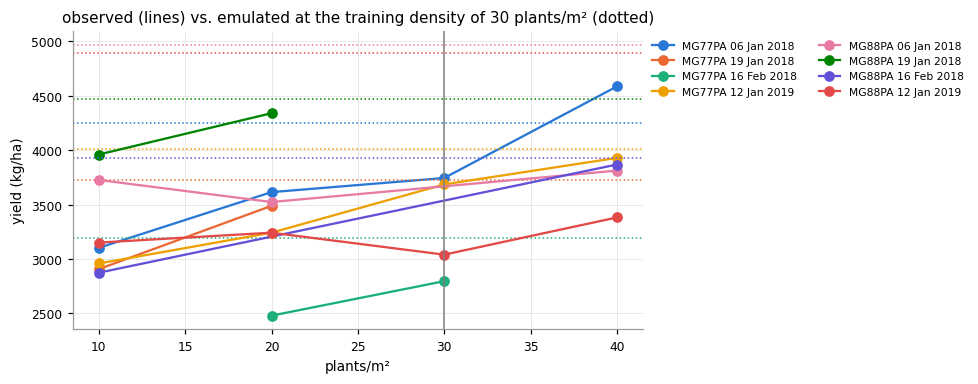

In [33]:
d = field[field["trial"] == "PARA1801"]
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, ((cv, sow), g) in enumerate(d.groupby(["cultivar", "sowing"])):
    g = g.sort_values("plants_m2")
    ax.plot(g["plants_m2"], g["obs_yield"], marker="o", color=SERIES[i % len(SERIES)], label=f"{cv[:6]} {sow:%d %b %Y}")
    ax.axhline(g["yield"].iloc[0], color=SERIES[i % len(SERIES)], lw=1, ls=":")
ax.axvline(30, color="0.5", lw=1)
ax.set(xlabel="plants/m²", ylabel="yield (kg/ha)", title="observed (lines) vs. emulated at the training density of 30 plants/m² (dotted)")
ax.legend(ncol=2, fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout(); plt.show()

**Reading the comparison.** The dates are close to the observations (anthesis within a
few days); the yields scatter more, as expected from a crop model that was not calibrated for these
sites and from what the emulator does not see (density, nitrogen, diseases, the exact irrigation).
The hollow points warn where the inputs left the training data: the sandy soil of Gainesville and
the calibrated cultivars of the studies. Their predictions are extrapolations.

### 11.5 Calibration with the emulator

The Paragominas trial was designed for calibration (2018) and evaluation (2019). The calibrated
cultivars of the study fall outside the training domain (11.3), so here the cultivar is calibrated
**inside** it, starting from the default cultivar of a maturity group:

1. the MG (0.05 steps) that best reproduces the observed anthesis and maturity dates of 2018;
2. then the maximum leaf photosynthesis `LFMAX` and the seed filling duration `SFDUR` (a grid
   inside their training range) that best reproduce the 2018 yields (densities 20-40 plants/m²);
3. evaluation on 2019, which the calibration never saw.

The inputs of every season are computed once (`emu.inputs`); trying a cultivar only changes the
cultivar columns and runs the network (`emu.predict_inputs`), so a grid of thousands of cultivars ×
seasons takes a fraction of a second.

When the best value lies on the edge of the training range, the observations ask for parameters the
emulator never saw: the calibration stops there, and going further needs the crop model itself.

In [34]:
para = field[(field["trial"] == "PARA1801") & (field["plants_m2"] >= 20)].copy()
para["year"] = para["sowing"].dt.year
s = SITES["PARA"]

def season_table(rows, cultivar):
    """Emulator inputs of each season (one row per treatment) for a starting cultivar."""
    X = [emu.inputs(season_weather("PARA", r.sowing), lat=s["lat"], elev=s["elev"], soil=soils["PARA"],
                    sowing=r.sowing, cultivar=cultivar) for r in rows.itertuples()]
    return pd.concat(X, ignore_index=True)

t0 = time.time()
calib = {}
for cv in ("MG77PA (13)", "MG88PA (13)"):
    cal, val = para[(para["cultivar"] == cv) & (para["year"] == 2018)], para[(para["cultivar"] == cv) & (para["year"] == 2019)]
    Xc, Xv = season_table(cal, emu.cultivar(mg=8)), season_table(val, emu.cultivar(mg=8))
    # step 1: MG from the dates
    mgs = np.round(np.arange(5.0, 10.0001, 0.05), 2)
    big = pd.concat([Xc.assign(**emu.cultivar(mg=m)) for m in mgs], ignore_index=True)
    P = emu.predict_inputs(big).outputs
    err = ((P["ADAT_dap"].to_numpy() - np.tile(cal["obs_anthesis"].to_numpy(), len(mgs))) ** 2 +
           (P["MDAT_dap"].to_numpy() - np.tile(cal["obs_maturity"].to_numpy(), len(mgs))) ** 2).reshape(len(mgs), -1)
    rmse_mg = np.sqrt(err.mean(axis=1) / 2)
    mg = float(mgs[rmse_mg.argmin()])
    # step 2: LFMAX x SFDUR from the yields
    d = emu.card["domain"]
    grid = [(a, b) for a in np.linspace(d["LFMAX"]["min"], d["LFMAX"]["max"], 15)
            for b in np.linspace(d["SFDUR"]["min"], d["SFDUR"]["max"], 15)]
    big = pd.concat([Xc.assign(**emu.cultivar(mg=mg, LFMAX=a, SFDUR=b)) for a, b in grid], ignore_index=True)
    Y = emu.predict_inputs(big).outputs["HWAM"].to_numpy().reshape(len(grid), -1)
    rmse_y = np.sqrt(((Y - cal["obs_yield"].to_numpy()) ** 2).mean(axis=1))
    a, b = grid[int(rmse_y.argmin())]
    best = emu.cultivar(mg=mg, LFMAX=a, SFDUR=b)
    calib[cv] = dict(cultivar=best, rmse_mg=rmse_mg, mgs=mgs, rmse_y=rmse_y.reshape(15, 15), grid=grid,
                     val=val.assign(**{k + "_cal": v for k, v in emu.predict_inputs(Xv.assign(**best)).outputs[
                         ["HWAM", "ADAT_dap", "MDAT_dap"]].set_axis(val.index).items()}),
                     n=len(big) + len(mgs) * len(Xc))
    print(f"{cv}: MG {mg:.2f}, LFMAX {a:.3f}, SFDUR {b:.2f}  ({calib[cv]['n']} emulated seasons)")
print(f"calibration time: {time.time() - t0:.1f} s (including the inputs from daily weather)")

MG77PA (13): MG 7.20, LFMAX 1.184, SFDUR 25.50  (1956 emulated seasons)


MG88PA (13): MG 8.50, LFMAX 1.066, SFDUR 25.50  (1304 emulated seasons)
calibration time: 1.9 s (including the inputs from daily weather)


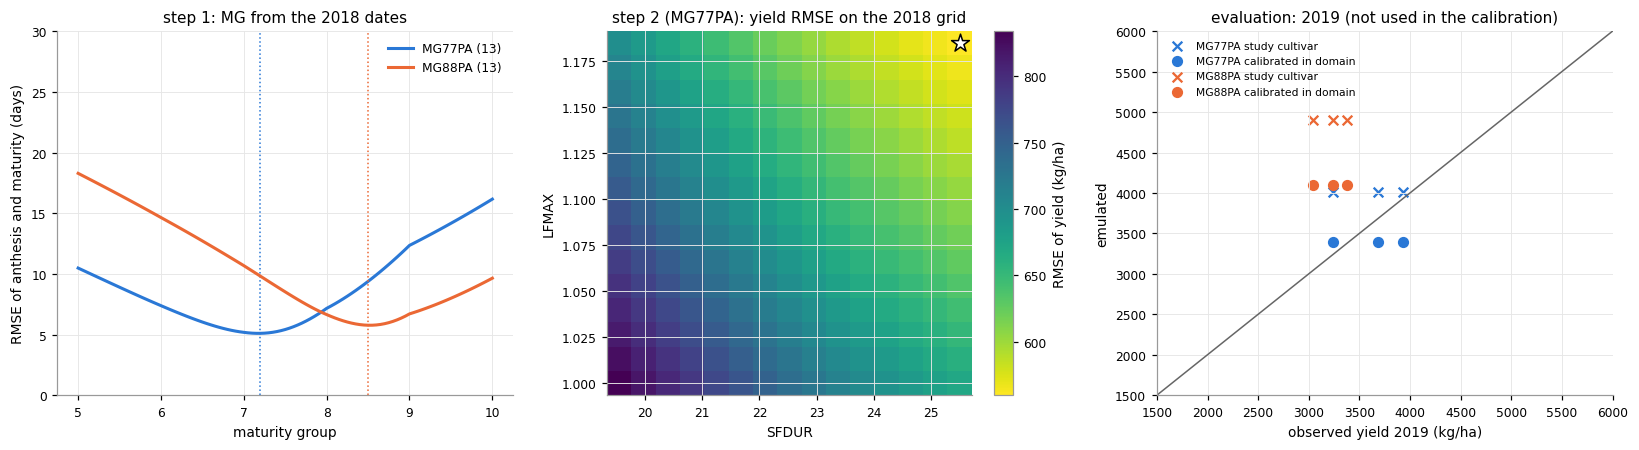

,study cultivar (out of domain),calibrated inside the domain
yield RMSE (kg/ha),1238.9,675.4
anthesis RMSE (d),2.4,8.3
maturity RMSE (d),12.5,7.8


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for i, (cv, c) in enumerate(calib.items()):
    ax.plot(c["mgs"], c["rmse_mg"], color=SERIES[i], lw=2, label=cv)
    ax.axvline(c["cultivar"]["mg"], color=SERIES[i], lw=1, ls=":")
ax.set(xlabel="maturity group", ylabel="RMSE of anthesis and maturity (days)", title="step 1: MG from the 2018 dates", ylim=(0, 30))
ax.legend()
ax = axes[1]
c = calib["MG77PA (13)"]
lf = np.unique([g[0] for g in c["grid"]]); sf = np.unique([g[1] for g in c["grid"]])
im = ax.pcolormesh(sf, lf, c["rmse_y"], cmap="viridis_r", shading="nearest")
ax.scatter([c["cultivar"]["SFDUR"]], [c["cultivar"]["LFMAX"]], marker="*", s=150, color="w", edgecolor="k")
plt.colorbar(im, ax=ax, label="RMSE of yield (kg/ha)")
ax.set(xlabel="SFDUR", ylabel="LFMAX", title="step 2 (MG77PA): yield RMSE on the 2018 grid")
ax = axes[2]
for i, (cv, c) in enumerate(calib.items()):
    v = c["val"]
    ax.scatter(v["obs_yield"], v["yield"], color=SERIES[i], marker="x", s=40, label=f"{cv[:6]} study cultivar")
    ax.scatter(v["obs_yield"], v["HWAM_cal"], color=SERIES[i], s=40, label=f"{cv[:6]} calibrated in domain")
lim = [1500, 6000]; ax.plot(lim, lim, color="0.4", lw=1); ax.set(xlim=lim, ylim=lim)
ax.set(xlabel="observed yield 2019 (kg/ha)", ylabel="emulated", title="evaluation: 2019 (not used in the calibration)")
ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

ev = pd.concat([c["val"].assign(cv=cv) for cv, c in calib.items()])
pd.DataFrame({
    "study cultivar (out of domain)": [scores(ev, "obs_yield", "yield")["RMSE"], scores(ev, "obs_anthesis", "anthesis")["RMSE"],
                                       scores(ev, "obs_maturity", "maturity")["RMSE"]],
    "calibrated inside the domain": [scores(ev, "obs_yield", "HWAM_cal")["RMSE"], scores(ev, "obs_anthesis", "ADAT_dap_cal")["RMSE"],
                                     scores(ev, "obs_maturity", "MDAT_dap_cal")["RMSE"]]},
    index=["yield RMSE (kg/ha)", "anthesis RMSE (d)", "maturity RMSE (d)"]).round(1)

### 11.6 Export the results

Predictions are `pandas` tables: save them with `to_csv` (or `to_excel` with `openpyxl`,
`to_parquet` with `pyarrow`). Keep the inputs and the domain flags with them.

In [36]:
out_dir = Path("results"); out_dir.mkdir(exist_ok=True)
field.to_csv(out_dir / f"field_trials_{emu.card['name']}.csv", index=False)
pd.DataFrame({cv: c["cultivar"] for cv, c in calib.items()}).to_csv(out_dir / f"calibrated_cultivars_{emu.card['name']}.csv")
print(sorted(p.name for p in out_dir.iterdir()))

['calibrated_cultivars_dssat-soybean-v1.csv', 'field_trials_dssat-soybean-v1.csv']


## Notes

- The emulator reproduces the crop model, not field yields: model errors are inherited, and the
  crop model was not calibrated for these sites.
- Fixed in training: 30 plants/m², 50 cm rows, no nitrogen stress, half of the available water 30
  days before sowing. Seasons with other management are outside what the emulator knows.
- Check `out_of_domain` and `rare_inputs` before trusting a season, and prefer the outputs of
  `recommended("caution")`.